In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import joblib
from pathlib import Path
from sklearn.inspection import permutation_importance

ROOT = Path(r"D:\Instant AI\AI\Graduation Project\RetainAI")
model = joblib.load(ROOT / "models" / "best_model.joblib")

print("Model loaded successfully!")

Model loaded successfully!


In [2]:
df = pd.read_csv(ROOT / "data" / "processed" / "telco_clean.csv")

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})
print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

In [4]:
importance = permutation_importance(
    model, X_val, y_val, scoring="average_precision", n_repeats=5, random_state=42, n_jobs=-1
)

importance_df=pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

importance_df.head()

,Feature,Importance
4,tenure,0.273291
7,InternetService,0.077240
14,Contract,0.060911
18,TotalCharges,0.058137
17,MonthlyCharges,0.043222


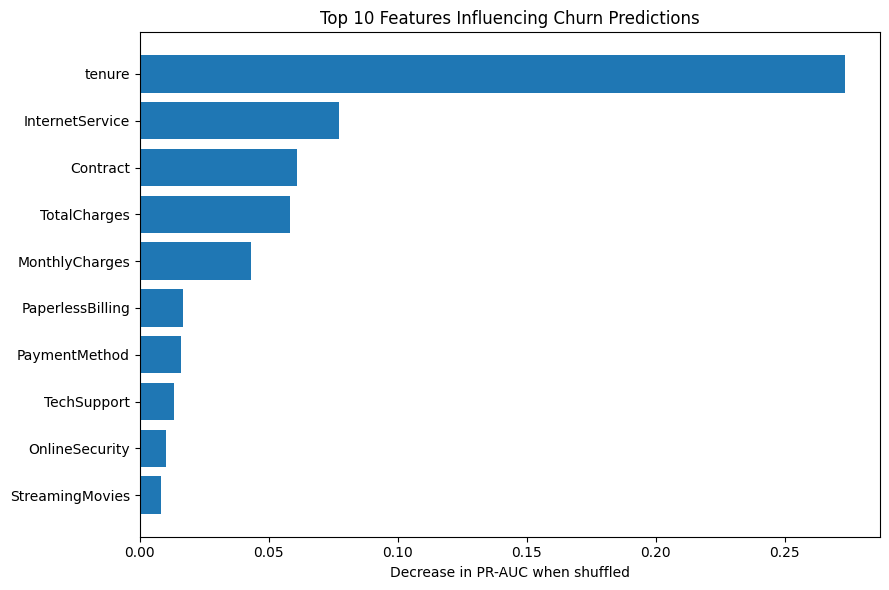

In [5]:
top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Decrease in PR-AUC when shuffled")
plt.title("Top 10 Features Influencing Churn Predictions")
plt.tight_layout()
plt.show()

## Key Findings

- **Tenure is the strongest predictive feature:** Customer relationship length contributes the most to the model's ability to identify churn.
- **Service type matters:** Internet service type provides additional information for distinguishing churners from non-churners.
- **Contract type is important:** Contract arrangements contribute to churn prediction and may help identify customer groups that need retention attention.
- **Charges contribute to prediction:** Both total and monthly charges provide useful information alongside tenure and service characteristics.

## Business Recommendations

1. Prioritize monitoring newer customers and consider targeted onboarding and early-retention campaigns.
2. Analyze churn rates across internet service and contract categories to identify higher-risk customer segments.
3. Review pricing and customer-value patterns before designing retention offers.
4. Use model predictions to prioritize retention outreach, then evaluate campaign results to measure actual impact.

*These findings describe predictive relationships, not proven causes of churn. Segment-level churn rates and further analysis are needed before making specific claims about which customers are at greatest risk.*